In [9]:
# Project objective and problem definition
print("Customer Churn Prediction using ANN")

Customer Churn Prediction using ANN



## 2. Import Libraries


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

## 3. Dataset Collection

In [52]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/shiyalkishan01/ibm-telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [12]:
df = pd.read_csv(
    "/kaggle/input/datasets/shiyalkishan01/ibm-telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Exploratory Data Analysis (EDA)

In [13]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [15]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [16]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0



## 5. Data Preprocessing

Churn distribution

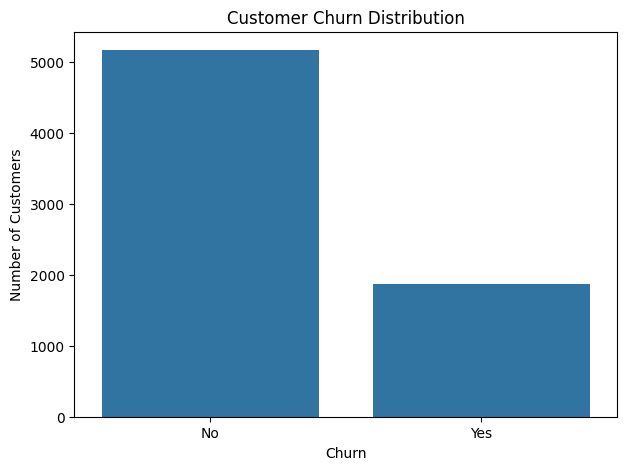

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Monthly charges vs churn

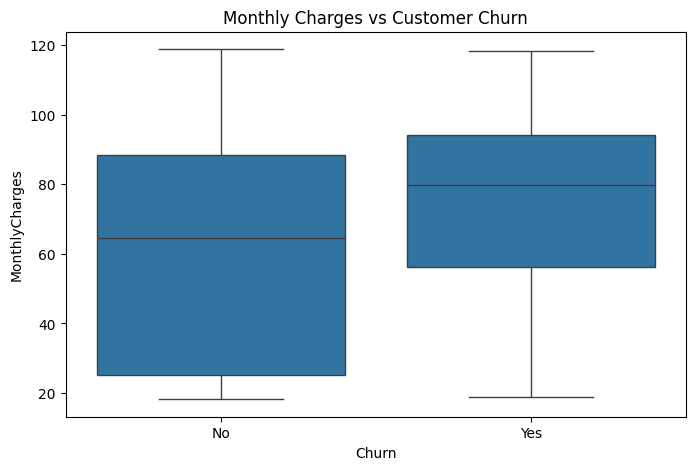

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")

plt.show()

Tenure vs churn

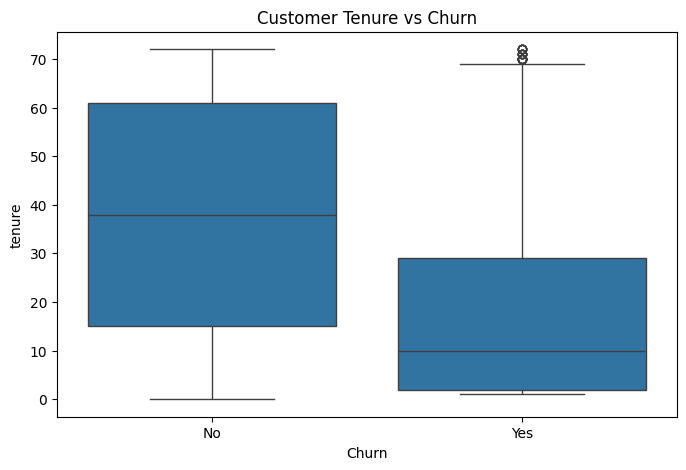

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")

plt.show()

# Check blank values in TotalCharges

In [21]:
print("Blank TotalCharges:",
      (df["TotalCharges"].str.strip() == "").sum())

print("Data type:", df["TotalCharges"].dtype)

Blank TotalCharges: 11
Data type: object


# Convert TotalCharges into numeric

In [22]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing values after conversion:")
print(df.isnull().sum())

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


# Check missing values

In [23]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


# Remove rows containing missing values

In [24]:
df = df.dropna()

print("Dataset shape after removing missing values:", df.shape)

print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after removing missing values: (7032, 21)
Remaining missing values: 0


# Remove customerID

In [25]:
df = df.drop("customerID", axis=1)

print(df.shape)

(7032, 20)


# Separate independent and dependent variables

In [26]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [27]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


Split numerical and categorical columns

In [28]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_cols)

print("\nCategorical columns:", categorical_cols)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Train-Test Split

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(type(X_train))
print(type(X_test))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


### Feature Scaling and One-Hot Encoding

In [30]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from scipy.sparse import issparse

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# Fit on training data
X_train = preprocessor.fit_transform(X_train)

# Transform testing data
X_test = preprocessor.transform(X_test)

# Convert sparse matrices only when necessary
if issparse(X_train):
    X_train = X_train.toarray()

if issparse(X_test):
    X_test = X_test.toarray()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5625, 45)
Testing shape: (1407, 45)


### Converting Data into PyTorch Tensors

In [31]:
# Convert features into float32 tensors

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

# Convert targets into float32 tensors

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("X_test:", X_test_tensor.shape)

print("y_train:", y_train_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([5625, 45])
X_test: torch.Size([1407, 45])
y_train: torch.Size([5625, 1])
y_test: torch.Size([1407, 1])


##  Building the Artificial Neural Network

###  Creating DataLoader

In [32]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create testing dataset
test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 176
Testing batches: 44


### Defining ANN Architecture
Creating a feedforward neural network with two hidden layers using PyTorch.

In [33]:
import torch
import torch.nn as nn

# Define ANN architecture

class CustomerChurnANN(nn.Module):

    def __init__(self, input_size):

        super(CustomerChurnANN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)

        )

    def forward(self, x):

        return self.network(x)


# Get number of input features
input_size = X_train_tensor.shape[1]

# Create model
model = CustomerChurnANN(input_size)

print(model)

CustomerChurnANN(
  (network): Sequential(
    (0): Linear(in_features=45, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


### Loss Function and Optimizer

Using Binary Cross Entropy with Logits as the loss function and Adam as the optimizer.

In [34]:
# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Training the ANN

Training the neural network using forward propagation,
loss calculation and backpropagation.

In [35]:
# Number of training epochs
epochs = 50

# Training loop
for epoch in range(epochs):

    model.train()

    total_loss = 0

    for inputs, targets in train_loader:

        # Forward propagation
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, targets)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {avg_loss:.4f}"
        )

Epoch [5/50], Loss: 0.4116
Epoch [10/50], Loss: 0.4051
Epoch [15/50], Loss: 0.4016
Epoch [20/50], Loss: 0.3972
Epoch [25/50], Loss: 0.3929
Epoch [30/50], Loss: 0.3913
Epoch [35/50], Loss: 0.3859
Epoch [40/50], Loss: 0.3838
Epoch [45/50], Loss: 0.3808
Epoch [50/50], Loss: 0.3783


### Model Evaluation

Evaluating the trained ANN on unseen testing data using
accuracy, precision, recall, F1-score and ROC-AUC.

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_probabilities = []
all_targets = []

with torch.no_grad():

    for inputs, targets in test_loader:

        logits = model(inputs)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(predictions.cpu().numpy().flatten())
        all_probabilities.extend(probabilities.cpu().numpy().flatten())
        all_targets.extend(targets.cpu().numpy().flatten())


# Calculate evaluation metrics

print("Accuracy:", accuracy_score(all_targets, all_predictions))

print("Precision:", precision_score(all_targets, all_predictions))

print("Recall:", recall_score(all_targets, all_predictions))

print("F1 Score:", f1_score(all_targets, all_predictions))

print("ROC-AUC:", roc_auc_score(all_targets, all_probabilities))

print("\nClassification Report:")
print(classification_report(all_targets, all_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(all_targets, all_predictions))

Accuracy: 0.7818052594171997
Precision: 0.5954415954415955
Recall: 0.5588235294117647
F1 Score: 0.576551724137931
ROC-AUC: 0.8276954097664764

Classification Report:
              precision    recall  f1-score   support

         0.0       0.84      0.86      0.85      1033
         1.0       0.60      0.56      0.58       374

    accuracy                           0.78      1407
   macro avg       0.72      0.71      0.71      1407
weighted avg       0.78      0.78      0.78      1407


Confusion Matrix:
[[891 142]
 [165 209]]


In [37]:
torch.save(
    model.state_dict(),
    "ann_customer_churn.pth"
)

print("Model saved successfully!")

Model saved successfully!


##  Advanced Model Evaluation

###  ROC Curve

Evaluating the classification performance of the ANN using the Receiver Operating Characteristic curve and Area Under the Curve.

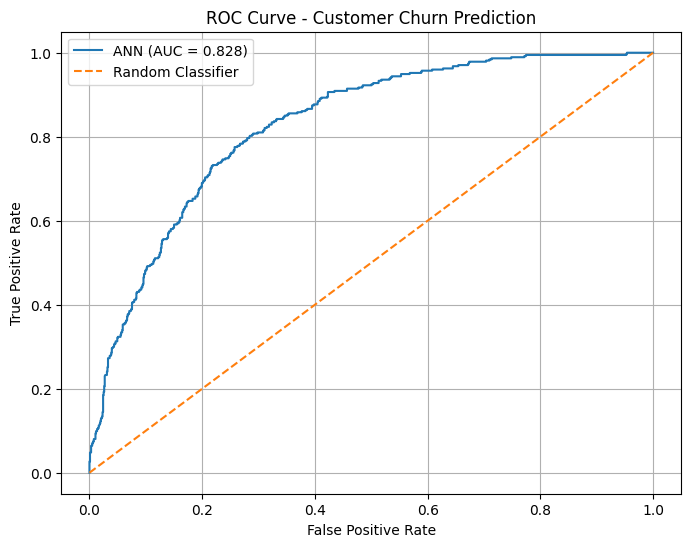

ROC-AUC Score: 0.8276954097664764


In [38]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC values

fpr, tpr, thresholds = roc_curve(
    all_targets,
    all_probabilities
)

# Calculate AUC

roc_auc = roc_auc_score(
    all_targets,
    all_probabilities
)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Customer Churn Prediction")

plt.legend()
plt.grid()

plt.show()

print("ROC-AUC Score:", roc_auc)

###  Precision-Recall Curve

Evaluating the trade-off between precision and recall for churn prediction.

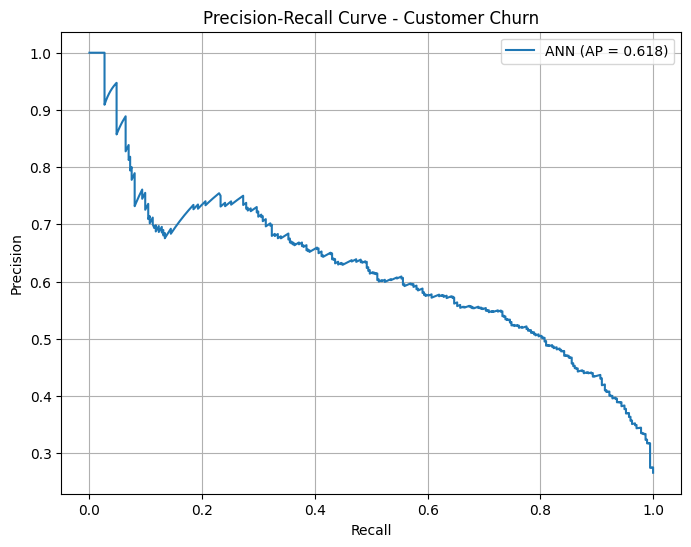

Average Precision: 0.6182951461124222


In [39]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Calculate precision and recall

precision, recall, pr_thresholds = precision_recall_curve(
    all_targets,
    all_probabilities
)

# Calculate Average Precision

avg_precision = average_precision_score(
    all_targets,
    all_probabilities
)

# Plot curve

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"ANN (AP = {avg_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - Customer Churn")

plt.legend()
plt.grid()

plt.show()

print("Average Precision:", avg_precision)

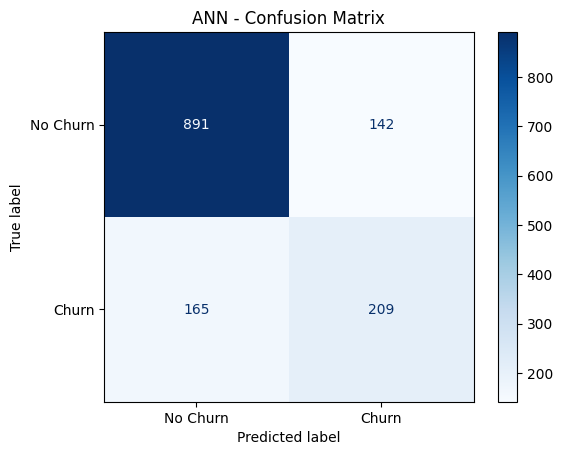

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    all_targets,
    all_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("ANN - Confusion Matrix")
plt.show()

In [41]:
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(avg_precision, 4))

ROC-AUC: 0.8277
Average Precision: 0.6183


### Classification Threshold Optimization

Experimenting with different classification thresholds to understand their impact on precision, recall and F1-score.

In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    predictions = [
        1 if probability >= threshold else 0
        for probability in all_probabilities
    ]

    precision = precision_score(all_targets, predictions)
    recall = recall_score(all_targets, predictions)
    f1 = f1_score(all_targets, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")


Threshold: 0.3
Precision: 0.4951
Recall:    0.8102
F1 Score:  0.6146

Threshold: 0.4
Precision: 0.5525
Recall:    0.7032
F1 Score:  0.6188

Threshold: 0.5
Precision: 0.5954
Recall:    0.5588
F1 Score:  0.5766

Threshold: 0.6
Precision: 0.6367
Recall:    0.4358
F1 Score:  0.5175

Threshold: 0.7
Precision: 0.6774
Recall:    0.3369
F1 Score:  0.4500


### Validation-Based Threshold Selection

Splitting the training dataset into training and validation sets to select an appropriate classification threshold without using the test dataset.

In [43]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# Split training indices
indices = np.arange(len(X_train_tensor))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_train_tensor.cpu().numpy().ravel()
)

# Create datasets
train_dataset = TensorDataset(
    X_train_tensor[train_idx],
    y_train_tensor[train_idx]
)

val_dataset = TensorDataset(
    X_train_tensor[val_idx],
    y_train_tensor[val_idx]
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 4500
Validation samples: 1125


### Retraining ANN with Validation Dataset

Retraining the neural network using the reduced training dataset and monitoring validation loss.

In [44]:
import copy

# Reinitialize model
model = CustomerChurnANN(input_size)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50
patience = 5

best_val_loss = float("inf")
best_epoch = 0
counter = 0

for epoch in range(epochs):

    # Training
    model.train()

    train_loss = 0

    for inputs, targets in train_loader:

        outputs = model(inputs)

        loss = criterion(outputs, targets)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # Validation
    model.eval()

    val_loss = 0

    with torch.no_grad():

        for inputs, targets in val_loader:

            outputs = model(inputs)

            loss = criterion(outputs, targets)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    # Early stopping
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        counter = 0

    else:

        counter += 1

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch {epoch+1}: "
            f"Train Loss={avg_train_loss:.4f}, "
            f"Val Loss={avg_val_loss:.4f}"
        )

    if counter >= patience:

        print("Early stopping triggered!")

        break


# Restore best model
model.load_state_dict(best_model_state)

print("\nBest Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

Epoch 5: Train Loss=0.4114, Val Loss=0.4333
Epoch 10: Train Loss=0.4072, Val Loss=0.4325
Early stopping triggered!

Best Epoch: 8
Best Validation Loss: 0.4315158774455388


In [45]:
model.eval()

val_probabilities = []
val_targets = []

with torch.no_grad():

    for inputs, targets in val_loader:

        logits = model(inputs)

        probabilities = torch.sigmoid(logits)

        val_probabilities.extend(
            probabilities.numpy().flatten()
        )

        val_targets.extend(
            targets.numpy().flatten()
        )

from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    predictions = [
        1 if p >= threshold else 0
        for p in val_probabilities
    ]

    precision = precision_score(val_targets, predictions, zero_division=0)

    recall = recall_score(val_targets, predictions, zero_division=0)

    f1 = f1_score(val_targets, predictions, zero_division=0)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")


Threshold: 0.3
Precision: 0.5522
Recall: 0.7258
F1 Score: 0.6272

Threshold: 0.4
Precision: 0.5723
Recall: 0.5953
F1 Score: 0.5836

Threshold: 0.5
Precision: 0.6157
Recall: 0.4983
F1 Score: 0.5508

Threshold: 0.6
Precision: 0.6894
Recall: 0.3712
F1 Score: 0.4826

Threshold: 0.7
Precision: 0.8000
Recall: 0.2140
F1 Score: 0.3377


In [46]:
model.eval()

val_probabilities = []
val_targets = []

with torch.no_grad():

    for inputs, targets in val_loader:

        logits = model(inputs)

        probabilities = torch.sigmoid(logits)

        val_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

        val_targets.extend(
            targets.cpu().numpy().flatten()
        )

In [47]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

best_threshold = 0.5
best_f1 = 0

for threshold in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7]:

    predictions = [
        1 if p >= threshold else 0
        for p in val_probabilities
    ]

    precision = precision_score(
        val_targets, predictions, zero_division=0
    )

    recall = recall_score(
        val_targets, predictions, zero_division=0
    )

    f1 = f1_score(
        val_targets, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1:

        best_f1 = f1
        best_threshold = threshold

print("\nBest Threshold:", best_threshold)
print("Best Validation F1:", best_f1)

Threshold: 0.20 | Precision: 0.4796 | Recall: 0.8261 | F1: 0.6069
Threshold: 0.25 | Precision: 0.5249 | Recall: 0.7759 | F1: 0.6262
Threshold: 0.30 | Precision: 0.5522 | Recall: 0.7258 | F1: 0.6272
Threshold: 0.35 | Precision: 0.5650 | Recall: 0.6689 | F1: 0.6126
Threshold: 0.40 | Precision: 0.5723 | Recall: 0.5953 | F1: 0.5836
Threshold: 0.45 | Precision: 0.6037 | Recall: 0.5452 | F1: 0.5729
Threshold: 0.50 | Precision: 0.6157 | Recall: 0.4983 | F1: 0.5508
Threshold: 0.60 | Precision: 0.6894 | Recall: 0.3712 | F1: 0.4826
Threshold: 0.70 | Precision: 0.8000 | Recall: 0.2140 | F1: 0.3377

Best Threshold: 0.3
Best Validation F1: 0.6271676300578035


In [48]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

test_probabilities = []
test_targets = []

with torch.no_grad():

    for inputs, targets in test_loader:

        logits = model(inputs)

        probabilities = torch.sigmoid(logits)

        test_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

        test_targets.extend(
            targets.cpu().numpy().flatten()
        )


# Apply selected validation threshold

test_predictions = [
    1 if p >= best_threshold else 0
    for p in test_probabilities
]

print("Selected Threshold:", best_threshold)

print("\nFinal Test Results:")

print(
    classification_report(
        test_targets,
        test_predictions,
        target_names=["No Churn", "Churn"]
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        test_targets,
        test_predictions
    )
)

Selected Threshold: 0.3

Final Test Results:
              precision    recall  f1-score   support

    No Churn       0.89      0.76      0.82      1033
       Churn       0.53      0.75      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.76      0.77      1407


Confusion Matrix:
[[784 249]
 [ 92 282]]


## Model Export and Artifact Saving

Saving the trained ANN model, preprocessing pipeline, and classification threshold for future predictions.

In [49]:
import os
import json
import torch
import joblib

# Create artifact directory
os.makedirs("/kaggle/working/model_artifacts", exist_ok=True)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "/kaggle/working/model_artifacts/preprocessor.pkl"
)

# Save trained ANN weights
torch.save(
    model.state_dict(),
    "/kaggle/working/model_artifacts/ann_customer_churn.pth"
)

# Save model configuration
metadata = {
    "input_size": int(X_train_tensor.shape[1]),
    "best_threshold": float(best_threshold),
    "best_epoch": int(best_epoch),
    "numerical_columns": numerical_cols,
    "categorical_columns": categorical_cols
}

with open(
    "/kaggle/working/model_artifacts/metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("All model artifacts saved successfully!")

All model artifacts saved successfully!


## Customer Churn Prediction Function

Creating a reusable function to predict whether a new customer is likely to churn.

In [55]:
def predict_churn(customer_data):

    # Ensure input is a DataFrame
    if isinstance(customer_data, dict):
        customer_data = pd.DataFrame([customer_data])

    if not isinstance(customer_data, pd.DataFrame):
        raise TypeError(
            "Input must be a Pandas DataFrame or dictionary."
        )

    # Select required columns
    required_columns = numerical_cols + categorical_cols

    customer_data = customer_data[required_columns].copy()

    # Convert numerical columns
    for col in numerical_cols:
        customer_data[col] = pd.to_numeric(
            customer_data[col], errors="coerce"
        )

    # Apply fitted preprocessing
    processed_data = preprocessor.transform(customer_data)

    # Convert sparse matrix if necessary
    if hasattr(processed_data, "toarray"):
        processed_data = processed_data.toarray()

    # Convert to tensor
    input_tensor = torch.tensor(
        processed_data,
        dtype=torch.float32
    )

    # Predict
    model.eval()

    with torch.no_grad():
        logits = model(input_tensor)
        probability = torch.sigmoid(logits).item()

    prediction = (
        "Churn"
        if probability >= best_threshold
        else "No Churn"
    )

    return {
        "Churn Probability": round(probability, 4),
        "Prediction": prediction,
        "Threshold": best_threshold
    }

In [56]:
print("X type:", type(X))
print("X shape:", X.shape)

print("X_test type:", type(X_test))
print("X_test shape:", X_test.shape)

X type: <class 'pandas.core.frame.DataFrame'>
X shape: (7032, 19)
X_test type: <class 'numpy.ndarray'>
X_test shape: (1407, 45)


In [57]:
sample_customer = X.iloc[[0]].copy()

result = predict_churn(sample_customer)

print("Customer Churn Prediction")
print("-------------------------")

for key, value in result.items():
    print(f"{key}: {value}")

Customer Churn Prediction
-------------------------
Churn Probability: 0.5473
Prediction: Churn
Threshold: 0.3


In [58]:
# Test predictions on 5 customers

sample_customers = X.iloc[:5].copy()

for i in range(len(sample_customers)):

    result = predict_churn(
        sample_customers.iloc[[i]]
    )

    print(f"\nCustomer {i+1}")
    print("Probability:", result["Churn Probability"])
    print("Prediction:", result["Prediction"])


Customer 1
Probability: 0.5473
Prediction: Churn

Customer 2
Probability: 0.0541
Prediction: No Churn

Customer 3
Probability: 0.2715
Prediction: No Churn

Customer 4
Probability: 0.0388
Prediction: No Churn

Customer 5
Probability: 0.6899
Prediction: Churn


In [59]:
import shutil

shutil.make_archive(
    "/kaggle/working/ann_model_artifacts",
    "zip",
    "/kaggle/working/model_artifacts"
)

print("Model artifacts packaged successfully!")

Model artifacts packaged successfully!
